In [5]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import glob
import os
import re

In [9]:
ds = xr.open_dataset('/media/unmesh/data31/TomoSense/SAR_data_NetCDF/P/NW/DataCube/Monostatic/ComplexSlice/tomo_slice_0m_HH.nc')
print(ds)

<xarray.Dataset>
Dimensions:                       (GroundRangeDim: 1274, CrossRangeDim: 12953,
                                   SigmaImageSingleLookRealPartCr: 12953,
                                   SigmaImageSingleLookRealPartGr: 1274,
                                   SigmaImageSingleLookImagPartCr: 12953,
                                   SigmaImageSingleLookImagPartGr: 1274)
Dimensions without coordinates: GroundRangeDim, CrossRangeDim,
                                SigmaImageSingleLookRealPartCr,
                                SigmaImageSingleLookRealPartGr,
                                SigmaImageSingleLookImagPartCr,
                                SigmaImageSingleLookImagPartGr
Data variables:
    GroundRange                   (GroundRangeDim) float32 ...
    CrossRange                    (CrossRangeDim) float32 ...
    SigmaImageSingleLookRealPart  (SigmaImageSingleLookRealPartCr, SigmaImageSingleLookRealPartGr) float32 ...
    SigmaImageSingleLookImagPart  (Sigma

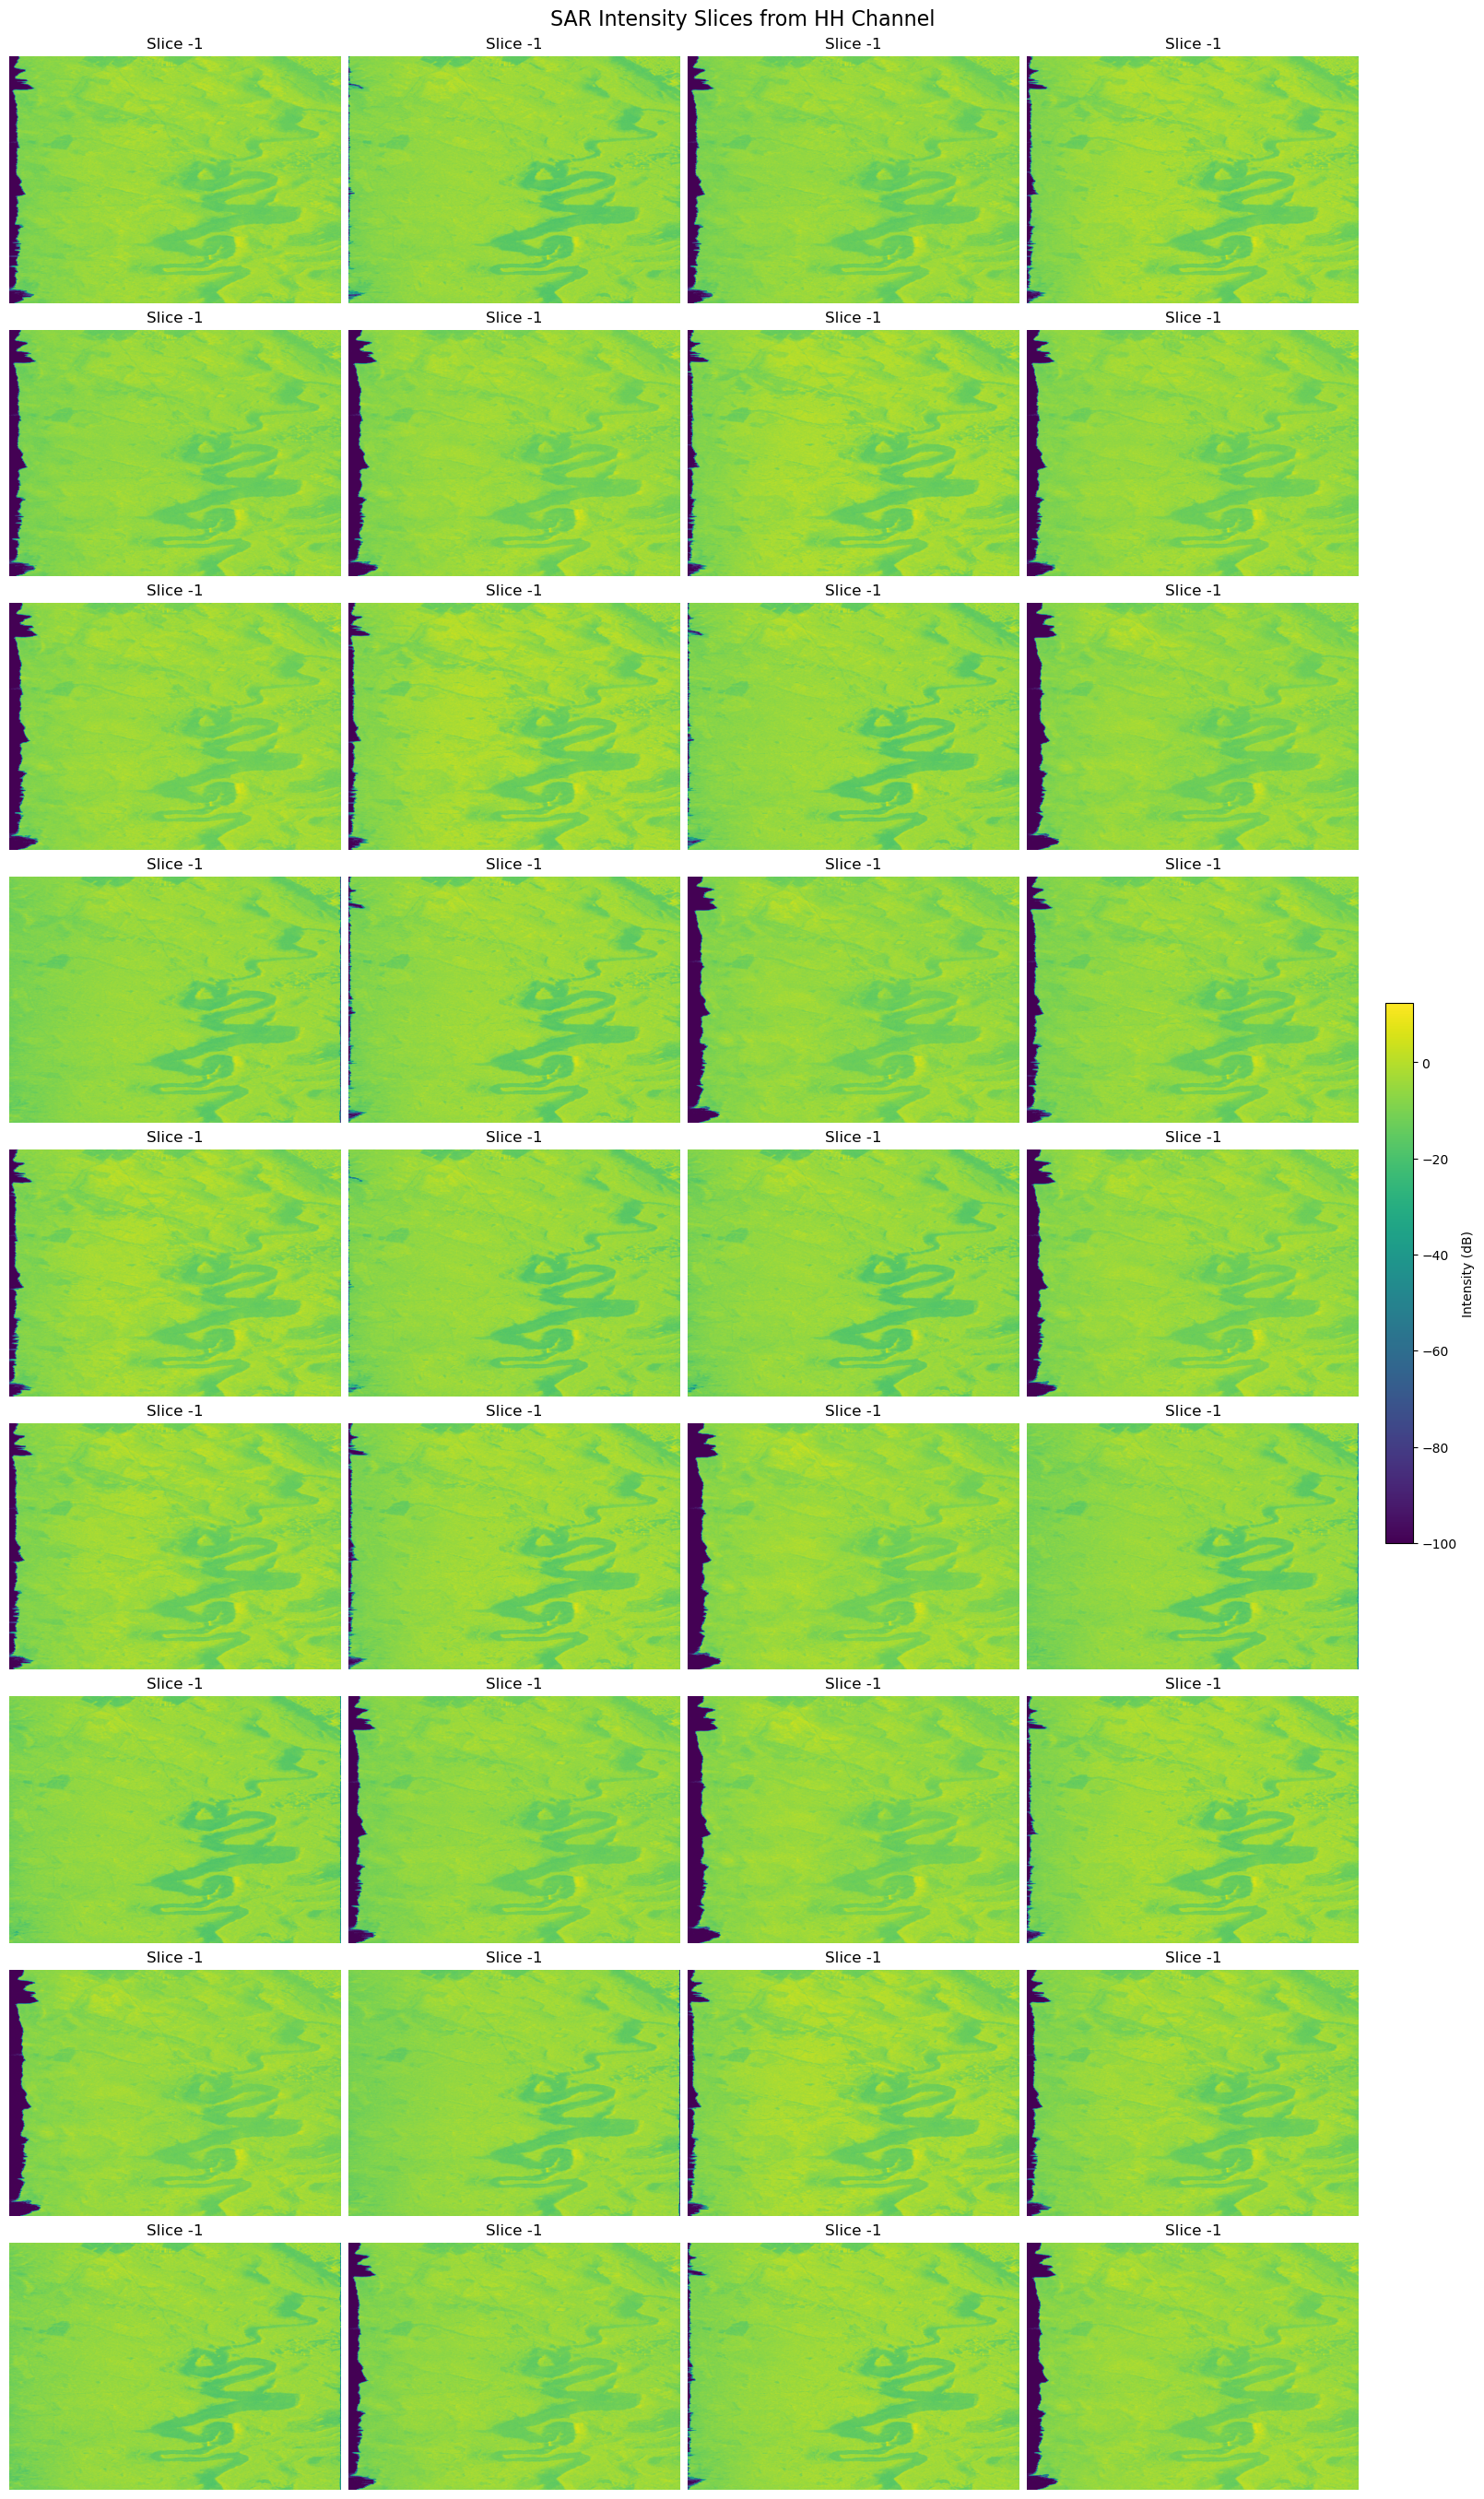

In [22]:

# Path pattern
path_pattern = "/media/unmesh/data31/TomoSense/SAR_data_NetCDF/P/NW/DataCube/Monostatic/ComplexSlice/tomo_slice_*_HH.nc"

# Collect and sort files numerically based on the number in the filename
def extract_index(filename):
    match = re.search(r'tomo_slice_(\d+)_HH\.nc', os.path.basename(filename))
    return int(match.group(1)) if match else -1

file_list = sorted(glob.glob(path_pattern), key=extract_index)

# Number of plots
n_files = len(file_list)
ncols = 4
nrows = int(np.ceil(n_files / ncols))

# Create subplots
fig, axs = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), constrained_layout=True)

for i, file in enumerate(file_list):
    ds = xr.open_dataset(file)
    
    real = ds['SigmaImageSingleLookRealPart'].values
    imag = ds['SigmaImageSingleLookImagPart'].values
    intensity = np.sqrt(real**2 + imag**2)
    intensity_db = 10 * np.log10(np.maximum(intensity, 1e-10))

    # Flatten subplot indexing
    ax = axs.flat[i]
    im = ax.imshow(intensity_db, cmap='viridis', aspect='auto')
    ax.set_title(f"Slice {extract_index(file)}")
    ax.axis('off')

# Remove unused subplots
for j in range(i + 1, nrows * ncols):
    fig.delaxes(axs.flat[j])

# Add a single colorbar
cbar = fig.colorbar(im, ax=axs, orientation='vertical', fraction=0.02, pad=0.02)
cbar.set_label('Intensity (dB)')

plt.suptitle("SAR Intensity Slices from HH Channel", fontsize=16)
plt.show()


# Util

In [11]:
ds1 = xr.open_dataset('/media/unmesh/data31/TomoSense/SAR_data_NetCDF/P/NW/Util/datacube/DataCube_ancillary_data.nc')
print(ds1)

<xarray.Dataset>
Dimensions:        (AzimuthSlopeCr: 12953, AzimuthSlopeGr: 1274,
                    GroundSlopeCr: 12953, GroundSlopeGr: 1274,
                    OffNadirAngleCr: 12953, OffNadirAngleGr: 1274)
Dimensions without coordinates: AzimuthSlopeCr, AzimuthSlopeGr, GroundSlopeCr,
                                GroundSlopeGr, OffNadirAngleCr, OffNadirAngleGr
Data variables:
    AzimuthSlope   (AzimuthSlopeCr, AzimuthSlopeGr) float32 ...
    GroundSlope    (GroundSlopeCr, GroundSlopeGr) float32 ...
    OffNadirAngle  (OffNadirAngleCr, OffNadirAngleGr) float32 ...


In [18]:
AzimuthSlope=ds1['AzimuthSlope'].values
GroundSlope=ds1['GroundSlope'].values
OffNadirAngle=ds1['OffNadirAngle'].values

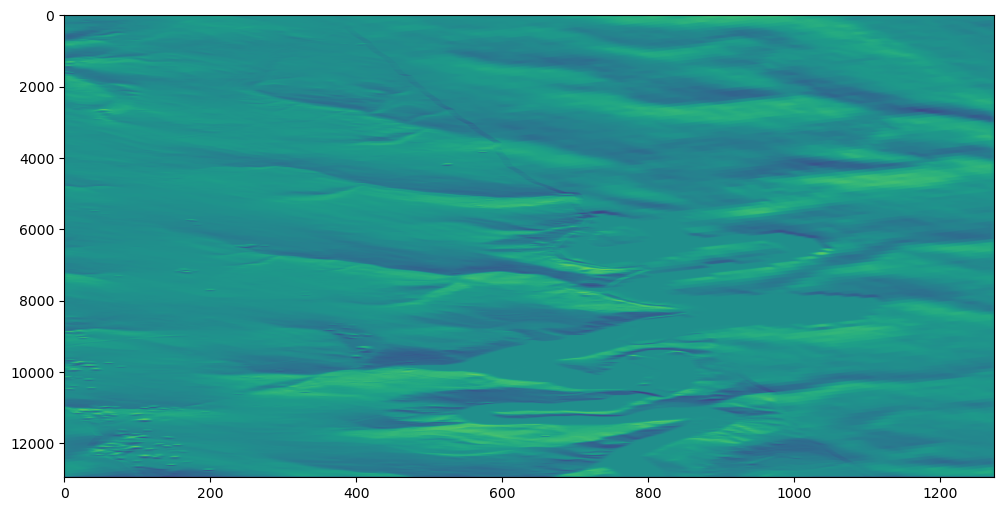

In [19]:
plt.figure(figsize=(12, 6))
plt.imshow(AzimuthSlope, cmap='viridis', aspect='auto')
plt.show()

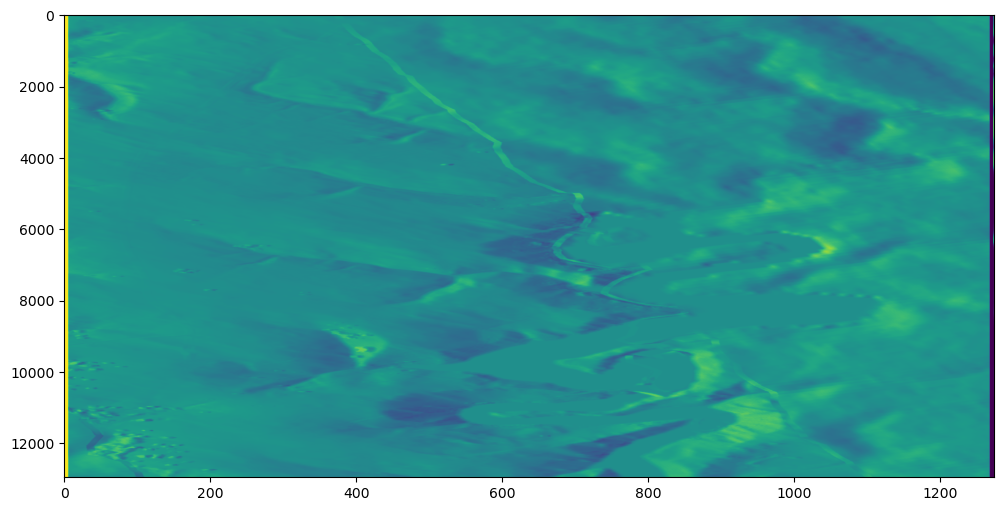

In [20]:

plt.figure(figsize=(12, 6))
plt.imshow(GroundSlope, cmap='viridis', aspect='auto')
plt.show()

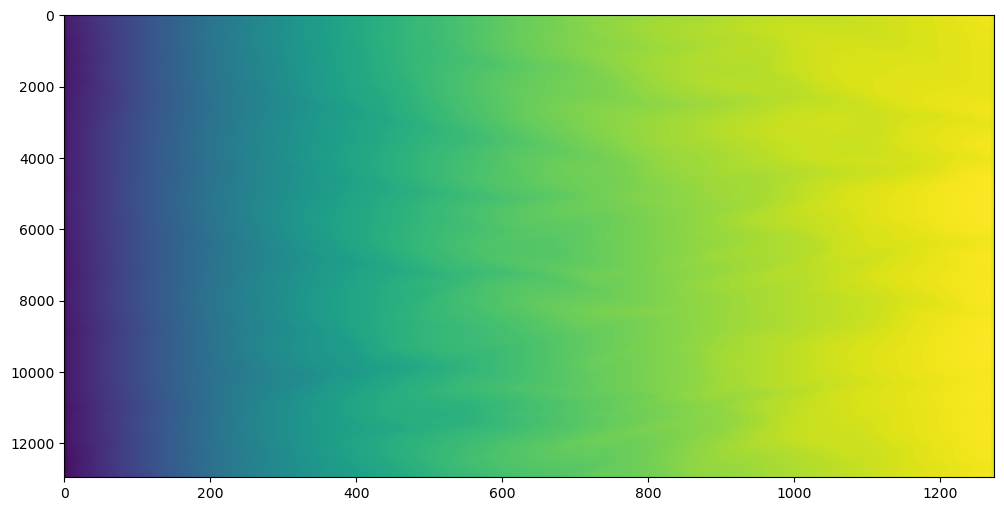

In [21]:
plt.figure(figsize=(12, 6))
plt.imshow(OffNadirAngle, cmap='viridis', aspect='auto')
plt.show()

In [23]:
ds2 = xr.open_dataset('/media/unmesh/data31/TomoSense/SAR_data_NetCDF/P/NW/Util/SLC/SLC_ancillary_data.nc')
print(ds2)

TomoDTMgr=ds2['TomoDTMgr'].values
TomoDTMsr=ds2['TomoDTMsr'].values
MetaSensingDTM=ds2['MetaSensingDTM'].values

plt.figure(figsize=(12, 6))
plt.imshow(TomoDTMgr, cmap='viridis', aspect='auto')
plt.show()

<xarray.Dataset>
Dimensions:         (TomoDTMgrCr: 12953, TomoDTMgrGr: 1274, TomoDTMsrCr: 12953,
                     TomoDTMsrGr: 1274, MetaSensingDTMCr: 12953,
                     MetaSensingDTMGr: 1274)
Dimensions without coordinates: TomoDTMgrCr, TomoDTMgrGr, TomoDTMsrCr,
                                TomoDTMsrGr, MetaSensingDTMCr, MetaSensingDTMGr
Data variables:
    TomoDTMgr       (TomoDTMgrCr, TomoDTMgrGr) float32 ...
    TomoDTMsr       (TomoDTMsrCr, TomoDTMsrGr) float32 ...
    MetaSensingDTM  (MetaSensingDTMCr, MetaSensingDTMGr) float32 ...


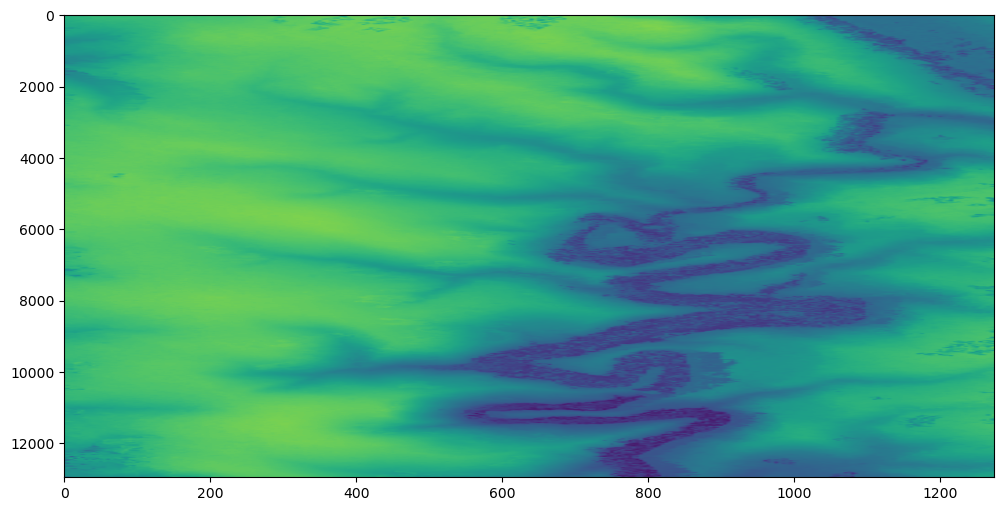

In [26]:
plt.figure(figsize=(12, 6))
plt.imshow(TomoDTMsr, cmap='viridis', aspect='auto')
plt.show()

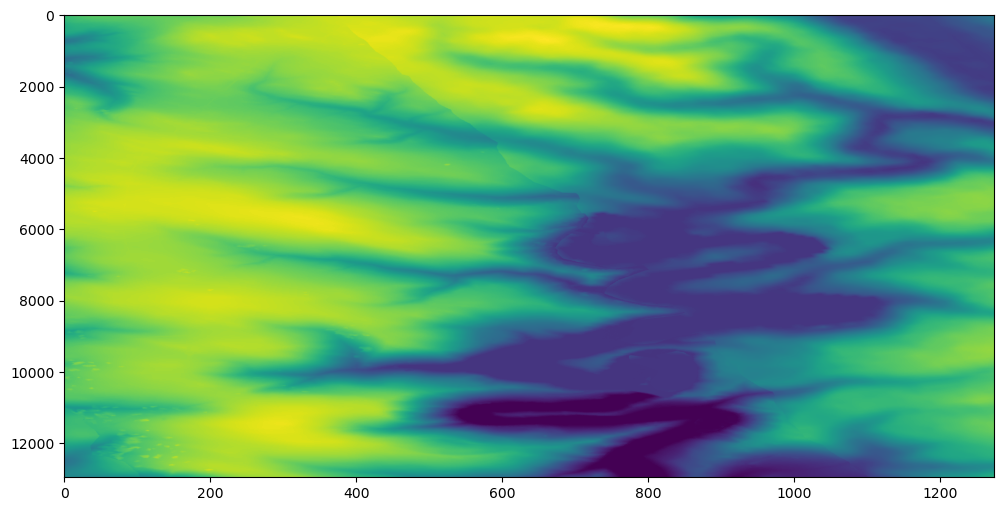

In [27]:
plt.figure(figsize=(12, 6))
plt.imshow(MetaSensingDTM, cmap='viridis', aspect='auto')
plt.show()

# SLC/Polimi

In [67]:
pattern = '/media/unmesh/data31/TomoSense/SAR_data_NetCDF/P/NW/SLC/PoliMi/*HH*.nc'

def extract_idx(fname):
    m = re.search(r'_(\d+)\.nc$', os.path.basename(fname))
    return int(m.group(1)) if m else -1

file_list = sorted(glob.glob(pattern), key=extract_idx)

ds2 = xr.open_dataset(file_list[0])


In [68]:
np.shape(file_list)

(28,)

In [69]:
ds2

<xarray.Dataset>
Dimensions:                       (GroundRangeDim: 1274, CrossRangeDim: 12953,
                                   TxOrbitGroundRangeDim: 12953,
                                   TxOrbitCrossRangeDim: 12953,
                                   TxOrbitElevationDim: 12953,
                                   RxOrbitGroundRangeDim: 12953,
                                   RxOrbitCrossRangeDim: 12953,
                                   RxOrbitElevationDim: 12953,
                                   SigmaImageSingleLookRealPartCr: 12953,
                                   SigmaImageSingleLookRealPartGr: 1274,
                                   SigmaImageSingleLookImagPartCr: 12953,
                                   SigmaImageSingleLookImagPartGr: 1274,
                                   kzCr: 12953, kzGr: 1274)
Dimensions without coordinates: GroundRangeDim, CrossRangeDim,
                                TxOrbitGroundRangeDim, TxOrbitCrossRangeDim,
                                TxOrbitElevationDim, RxOrbitGroundRangeDim,
                                RxOrbitCrossRangeDim, RxOrbitElevationDim,
                                SigmaImageSingleLookRealPartCr,
                                SigmaImageSingleLookRealPartGr,
                                SigmaImageSingleLookImagPartCr,
                                SigmaImageSingleLookImagPartGr, kzCr, kzGr
Data variables: (12/13)
    GroundRange                   (GroundRangeDim) float32 ...
    CrossRange                    (CrossRangeDim) float32 ...
    TxOrbitGroundRange            (TxOrbitGroundRangeDim) float32 ...
    TxOrbitCrossRange             (TxOrbitCrossRangeDim) float32 ...
    TxOrbitElevation              (TxOrbitElevationDim) float32 ...
    RxOrbitGroundRange            (RxOrbitGroundRangeDim) float32 ...
    ...                            ...
    RxOrbitElevation              (RxOrbitElevationDim) float32 ...
    SigmaImageSingleLookRealPart  (SigmaImageSingleLookRealPartCr, SigmaImageSingleLookRealPartGr) float32 ...
    SigmaImageSingleLookImagPart  (SigmaImageSingleLookImagPartCr, SigmaImageSingleLookImagPartGr) float32 ...
    kz                            (kzCr, kzGr) float32 ...
    MonostaticFlag                float32 ...
    lambda                        float32 ...

In [70]:
kz=ds2['kz'].values

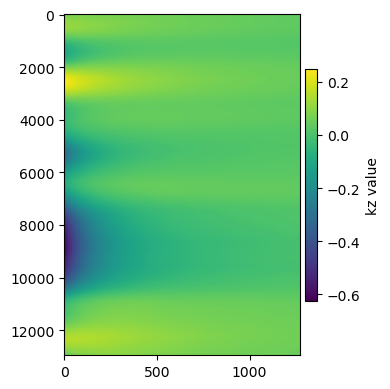

In [71]:
fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(kz, cmap='viridis', aspect='auto')
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
cbar.set_label('kz value')       
plt.tight_layout()
plt.show()

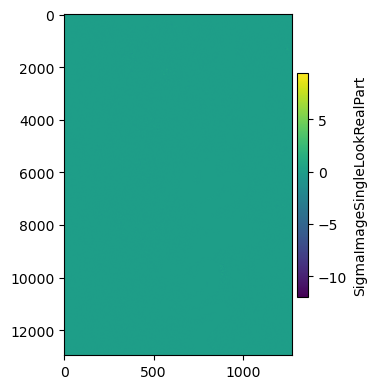

In [47]:
SigmaImageSingleLookRealPart=ds2['SigmaImageSingleLookRealPart'].values
fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(SigmaImageSingleLookRealPart, cmap='viridis', aspect='auto')
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
cbar.set_label('SigmaImageSingleLookRealPart')       
plt.tight_layout()
plt.show()

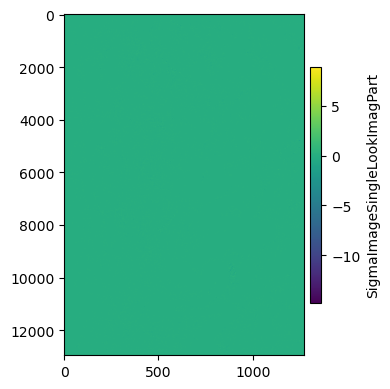

In [48]:
SigmaImageSingleLookImagPart=ds2['SigmaImageSingleLookImagPart'].values
fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(SigmaImageSingleLookImagPart, cmap='viridis', aspect='auto')
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
cbar.set_label('SigmaImageSingleLookImagPart')       
plt.tight_layout()
plt.show()

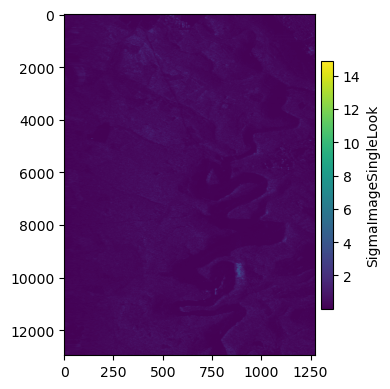

In [50]:
SigmaImageSingleLook = SigmaImageSingleLookRealPart + 1j * SigmaImageSingleLookImagPart
fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(np.abs(SigmaImageSingleLook), cmap='viridis', aspect='auto')
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
cbar.set_label('SigmaImageSingleLook')       
plt.tight_layout()
plt.show()

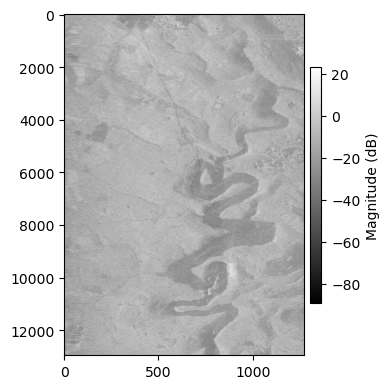

In [51]:
fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(20 * np.log10(np.abs(SigmaImageSingleLook) + 1e-10), cmap='gray', aspect='auto')
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
cbar.set_label('Magnitude (dB)')
plt.tight_layout()
plt.show()


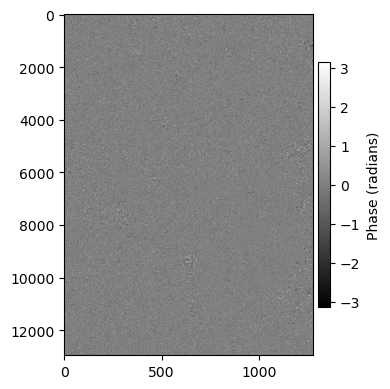

In [61]:
fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(np.angle(SigmaImageSingleLook), cmap='gray', aspect='auto')
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
cbar.set_label('Phase (radians)')
plt.tight_layout()
plt.show()
